# Rotation sandbox

In [1]:
import sys
sys.path.insert(0, "../")

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as colors
from matplotlib import ticker
from math import pi
from decimal import Decimal
from mosh_src.plotting_functions import *

In [3]:
# Set parameters for all plots in notebook
file = "/Users/seanmullane/Desktop/Research_2023/August_outputs/Results_08_07/1rod_12oclock_1e7_85bins_2.5cmHL.csv"
z_slice = 25
norm_point = (0.0, 0.3)
bins = 85
dose_grid_half = 2.5
lattice = dose_grid_half*2/bins
source_transZ = -0.5
source_plane = cm_to_voxel(np.array(source_transZ), bins, dose_grid_half*2/bins)
applicator_rad = 0.3

source_rad = [0.03, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
rngX = (-1.0, 1.0)
rngY = (-1.0, 1.0)

In [4]:
norm_energy, __ = extract_norm_energy(file, source_plane, 2, norm_point, bins, lattice)

In [5]:
X, Y, energy, __ = contour_energy(file, (bins, bins), dose_grid_half, source_plane, 2, rngX, rngY, source_rad=source_rad[4], 
                                               scale=True, norm_energy=norm_energy, zero_source=True, std_dev=False)

In [6]:
print(np.shape(energy))
print(X)
print(Y)

(33, 33)
[-0.94117647 -0.88235294 -0.82352941 -0.76470588 -0.70588235 -0.64705882
 -0.58823529 -0.52941176 -0.47058824 -0.41176471 -0.35294118 -0.29411765
 -0.23529412 -0.17647059 -0.11764706 -0.05882353  0.          0.05882353
  0.11764706  0.17647059  0.23529412  0.29411765  0.35294118  0.41176471
  0.47058824  0.52941176  0.58823529  0.64705882  0.70588235  0.76470588
  0.82352941  0.88235294  0.94117647]
[-0.94117647 -0.88235294 -0.82352941 -0.76470588 -0.70588235 -0.64705882
 -0.58823529 -0.52941176 -0.47058824 -0.41176471 -0.35294118 -0.29411765
 -0.23529412 -0.17647059 -0.11764706 -0.05882353  0.          0.05882353
  0.11764706  0.17647059  0.23529412  0.29411765  0.35294118  0.41176471
  0.47058824  0.52941176  0.58823529  0.64705882  0.70588235  0.76470588
  0.82352941  0.88235294  0.94117647]


In [7]:
# Define 2D rotation matrix - counterclockwise around origin through angle theta
def twoD_rot(theta: float) -> np.ndarray:
    return np.array([[np.cos(theta), -1*np.sin(theta)], [np.sin(theta), np.cos(theta)]])

In [8]:
rot_90 = twoD_rot(0)
print(rot_90)

[[ 1. -0.]
 [ 0.  1.]]


[-0.94117647 -0.94117647]
[-0.94117647 -0.94117647]


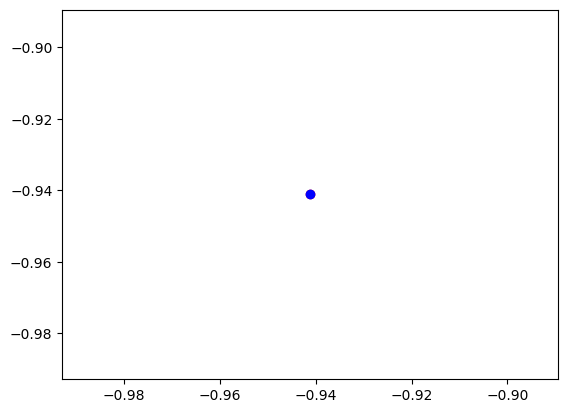

In [9]:
vector = np.array([X[0], Y[0]])
rotated_vector = rot_90 @ vector
print(vector)
print(rotated_vector)

fig1, ax1 = plt.subplots()
#ax1.set_ylim(-1.25, 1.25)
#ax1.set_xlim(-1.25, 1.25)
ax1.scatter(vector[0], vector[1], color="red")
ax1.scatter(rotated_vector[0], rotated_vector[1], color="blue")

33
[0 0]
[0 0]


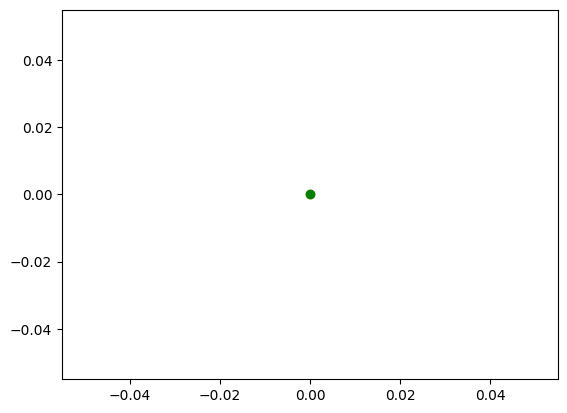

In [10]:
restricted_bin = np.shape(energy)[0]
print(restricted_bin)

voxel_1 = cm_to_voxel(vector, restricted_bin, lattice)
voxel_2 = cm_to_voxel(rotated_vector, restricted_bin, lattice)
print(voxel_1)
print(voxel_2)

fig2, ax2 = plt.subplots()
#ax2.set_ylim(0, restricted_bin)
#ax2.set_xlim(0, restricted_bin)
ax2.scatter(voxel_1[0], voxel_1[1], color="orange")
ax2.scatter(voxel_2[0], voxel_2[1], color="green")

In [11]:
# Naive algorithm - not sure if this will work - it's certainly not efficient
# Real space --> voxel space
# Declare rotated matrix
original_bins = np.shape(energy)
rotated_energy = np.zeros((original_bins[0] + 10, original_bins[1] + 10)) 

stored_voxels = np.array([])

# Iterate over all bins in region of interest
for x in X:
    for y in Y:
        # Define vector - cm space
        vector = np.array([x, y])

        # Extract voxel coordinates and energy
        vector_vox = cm_to_voxel(vector, restricted_bin, lattice)
        eng = energy[vector_vox[0]][vector_vox[1]]

        # Rotate vector in cm space
        rot_vector = rot_90 @ vector

        # Convert rotated vector to voxel space
        rot_vector_vox = cm_to_voxel(rot_vector, restricted_bin, lattice)
        
        # For readability
        new_x = rot_vector_vox[0]
        new_y = rot_vector_vox[1]
        #print(str(x) + " " + str(y) + " " + "//" + " " + str(new_x) + " " + str(new_y) + " " + str(rot_vector))

        # Assign energy to new cell in rotated matrix
        rotated_energy[new_x][new_y] = eng

new_X = voxel_to_cm(np.arange(0, original_bins[0] + 10), original_bins[0] + 10, lattice)
new_Y = voxel_to_cm(np.arange(0, original_bins[1] + 10), original_bins[1] + 10, lattice)
print(np.shape(new_X))
print(np.shape(new_Y))

print(new_X)

(43,)
(43,)
[-1.23529412 -1.17647059 -1.11764706 -1.05882353 -1.         -0.94117647
 -0.88235294 -0.82352941 -0.76470588 -0.70588235 -0.64705882 -0.58823529
 -0.52941176 -0.47058824 -0.41176471 -0.35294118 -0.29411765 -0.23529412
 -0.17647059 -0.11764706 -0.05882353  0.          0.05882353  0.11764706
  0.17647059  0.23529412  0.29411765  0.35294118  0.41176471  0.47058824
  0.52941176  0.58823529  0.64705882  0.70588235  0.76470588  0.82352941
  0.88235294  0.94117647  1.          1.05882353  1.11764706  1.17647059
  1.23529412]


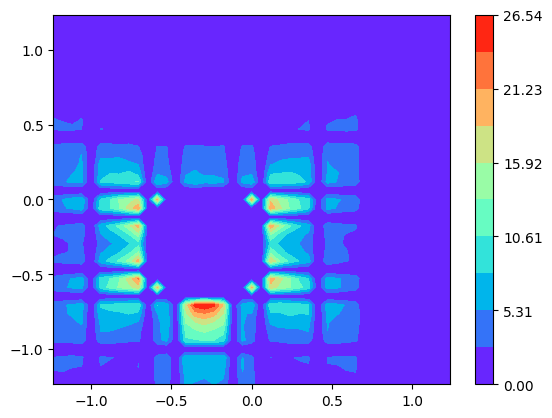

In [12]:
fig3, ax3 = plt.subplots()
contour = ax3.contourf(new_X, new_Y, rotated_energy, locator=ticker.LinearLocator(), norm="linear", cmap="rainbow")
cbar = fig3.colorbar(contour)
#circle = plt.Circle((0,0), radius=applicator_rad, edgecolor="red", fill=False)
#ax3.add_patch(circle)
#ax3.scatter(norm_point[0], norm_point[1], color="orange", marker="x")

### Rotation - high bin density

In [13]:
file1 = "/Users/seanmullane/Desktop/Research_2023/August_outputs/Results_08_11_1.0cmHL/2rod_14oclock_1e7_85bins_1.0cmHL.csv"
dose_grid_half_1 = 1.0
lattice_1 = dose_grid_half_1*2/bins

In [14]:
norm_energy_1, __ = extract_norm_energy(file1, source_plane, 2, norm_point, bins, lattice_1)

In [15]:
X1, Y1, energy1, __ = contour_energy(file1, (bins, bins), dose_grid_half_1, source_plane, 2, rngX, rngY, source_rad=source_rad[4], 
                                               scale=True, norm_energy=norm_energy, zero_source=True, std_dev=False)

In [16]:
# Naive algorithm
original_bins = np.shape(energy1)
rotated_energy1 = np.zeros((original_bins[0], original_bins[1])) 
restricted_bin_1 = np.shape(energy1)[0]

stored_voxels = np.array([])

# Iterate over all bins in region of interest
for x in X1:
    for y in Y1:
        # Define vector - cm space
        vector = np.array([x, y])

        # Extract voxel coordinates and energy
        vector_vox = cm_to_voxel(vector, restricted_bin_1, lattice_1)
        eng = energy1[vector_vox[0]][vector_vox[1]]

        # Rotate vector in cm space
        rot_vector = rot_90 @ vector

        # Convert rotated vector to voxel space
        rot_vector_vox = cm_to_voxel(rot_vector, restricted_bin_1, lattice_1)
        
        # For readability
        new_x = rot_vector_vox[0]
        new_y = rot_vector_vox[1]
        #print(str(x) + " " + str(y) + " " + "//" + " " + str(new_x) + " " + str(new_y) + " " + str(rot_vector))

        # Assign energy to new cell in rotated matrix
        rotated_energy1[new_x][new_y] = eng

new_X1 = voxel_to_cm(np.arange(0, original_bins[0]), original_bins[0], lattice)
new_Y1 = voxel_to_cm(np.arange(0, original_bins[1]), original_bins[1], lattice)

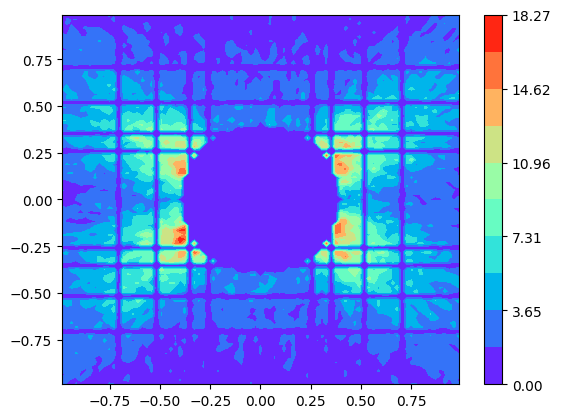

In [17]:
fig4, ax4 = plt.subplots()
contour = ax4.contourf(X1, Y1, rotated_energy1, locator=ticker.LinearLocator(), norm="linear", cmap="rainbow")
cbar = fig4.colorbar(contour)

### Testing cm ---> voxel ---> cm transformation

In [18]:
org_vector = np.array([X1[36], Y1[26]])
org_voxel = cm_to_voxel(vector, restricted_bin_1, lattice_1)
print("original vector: " + str(org_vector))
print("original voxel: " + str(org_voxel))

test_rot = twoD_rot(pi/2)
print(test_rot)

rot_vector_1 = test_rot @ org_vector
print("rotated vec before cm_to_voxel: " + str(rot_vector_1))

rot_vox = cm_to_voxel(rot_vector_1, restricted_bin_1, lattice_1)
print("rotated voxel: " + str(rot_vox))

rot_vector_2 = voxel_to_cm(rot_vox, restricted_bin_1, lattice_1)
print("rotated vector after cm_to_voxel: " + str(rot_vector_2))

print("org_vector dot rot_vector_2 = " + str(np.dot(org_vector, rot_vector_2)))
print("org_vector dot rot_vector_1 = " + str(np.dot(org_vector, rot_vector_1)))
print(np.dot(org_voxel, rot_vox)) # vectors not orthogonal in voxel space (different origin)

original vector: [-0.14117647 -0.37647059]
original voxel: [84 84]
[[ 6.123234e-17 -1.000000e+00]
 [ 1.000000e+00  6.123234e-17]]
rotated vec before cm_to_voxel: [ 0.37647059 -0.14117647]
rotated voxel: [58 36]
rotated vector after cm_to_voxel: [ 0.37647059 -0.14117647]
org_vector dot rot_vector_2 = 0.0
org_vector dot rot_vector_1 = 6.938893903907228e-18
7896
